# 04 — ViT-S/16 (SSL / ImageNet / random) як backbone DETR: крок 5

Ноутбук лише читає збережені артефакти: `reports/tables/phase4_*.csv` (з `scripts/compare_detr_runs.py` і `scripts/paired_detr_diff.py`) та `reports/figures/shift_<run>.png` (з `scripts/diagnose_shift.py`). Нічого не тренує й не оцінює. Пороги P/R/F1 обрано на val; test — лише фінальна оцінка (120 зображень, 303 infected GT), **один seed** на запуск.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from malaria_ssl.data.viz import SERIES
from malaria_ssl.detr.compare import plot_paired_diffs, plot_val_curves
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
runs = pd.read_csv(T / 'phase4_main_runs.csv').set_index('run')
diff = pd.read_csv(T / 'phase4_main_diff.csv')
curves = pd.read_csv(T / 'phase4_main_curves.csv', index_col='epochs_done')
COLORS = dict(zip(['b_vit_imagenet', 'b_vit_joint', 'b_vit_mae', 'b_vit_con', 'b_vit_random'], SERIES))

## Val і test: infected AP50 [95% CI], uninfected AP50

AP50 і їхні CI — з `metrics_{val,test}.json` (`evaluate.py --bootstrap`, 200 ресемплів). `best_epoch` — чекпоінт `best` (за val AP@[.5:.95]).

In [2]:
def fmt(r, k):
    return f"{r[k]:.3f} [{r[k + '_lo']:.3f}, {r[k + '_hi']:.3f}]"

pd.DataFrame({'best epoch': runs['best_epoch'],
              'val AP50 inf': [fmt(r, 'val_AP50_infected') for _, r in runs.iterrows()],
              'test AP50 inf': [fmt(r, 'test_AP50_infected') for _, r in runs.iterrows()],
              'val AP50 uninf': runs['val_AP50_uninfected'].round(3),
              'test AP50 uninf': [fmt(r, 'test_AP50_uninfected') for _, r in runs.iterrows()]})

,best epoch,val AP50 inf,test AP50 inf,val AP50 uninf,test AP50 uninf
run,,,,,
a_coco_detr_binary,40,"0.778 [0.728, 0.832]","0.551 [0.479, 0.622]",0.944,"0.970 [0.960, 0.980]"
b_vit_random,38,"0.711 [0.654, 0.769]","0.327 [0.267, 0.392]",0.942,"0.523 [0.488, 0.554]"
b_vit_imagenet,36,"0.769 [0.720, 0.833]","0.528 [0.469, 0.593]",0.947,"0.935 [0.920, 0.949]"
b_vit_mae,38,"0.762 [0.712, 0.825]","0.336 [0.266, 0.405]",0.957,"0.921 [0.907, 0.938]"
b_vit_con,38,"0.756 [0.706, 0.808]","0.251 [0.199, 0.300]",0.943,"0.899 [0.879, 0.919]"
b_vit_joint,32,"0.774 [0.717, 0.829]","0.329 [0.269, 0.399]",0.948,"0.921 [0.904, 0.938]"


## Test P / R / F1 infected при val-порозі

CI — з 1000 спільних bootstrap-ресемплів test-зображень (`paired_detr_diff.py`, seed 42).

In [3]:
pd.DataFrame({'val threshold': runs['threshold'].round(3),
              **{f'test {k}': [fmt(r, f'test_{k}') for _, r in runs.iterrows()]
                 for k in ('precision', 'recall', 'f1')}})

,val threshold,test precision,test recall,test f1
run,,,,
a_coco_detr_binary,0.867,"0.844 [0.787, 0.894]","0.376 [0.311, 0.447]","0.520 [0.455, 0.585]"
b_vit_random,0.821,"0.502 [0.448, 0.563]","0.432 [0.346, 0.527]","0.465 [0.404, 0.523]"
b_vit_imagenet,0.876,"0.838 [0.754, 0.910]","0.221 [0.172, 0.280]","0.350 [0.283, 0.422]"
b_vit_mae,0.794,"0.972 [0.906, 1.000]","0.116 [0.080, 0.162]","0.206 [0.147, 0.278]"
b_vit_con,0.890,"0.857 [0.636, 1.000]","0.020 [0.006, 0.037]","0.039 [0.013, 0.070]"
b_vit_joint,0.810,"0.821 [0.738, 0.901]","0.211 [0.163, 0.265]","0.336 [0.271, 0.403]"


## Діагностика зсуву (`diagnose_shift.py`)

Для кожної infected GT-клітини test: чи є infected-детекція з IoU ≥ 0.5 (інакше score 0), і чи вищий на ній score іншого класу (uninfected). Медіана — найкращого infected-score на GT-клітинах.

In [4]:
runs[['val_median_score', 'test_median_score', 'test_frac_ge_val_threshold',
      'test_frac_no_target_detection', 'test_frac_other_class_scores_higher']].round(3)

,val_median_score,test_median_score,test_frac_ge_val_threshold,test_frac_no_target_detection,test_frac_other_class_scores_higher
run,,,,,
a_coco_detr_binary,0.968,0.716,0.376,0.350,0.370
b_vit_random,0.950,0.540,0.432,0.452,0.386
b_vit_imagenet,0.973,0.235,0.221,0.208,0.624
b_vit_mae,0.952,0.000,0.116,0.571,0.690
b_vit_con,0.956,0.000,0.020,0.604,0.772
b_vit_joint,0.956,0.001,0.211,0.462,0.650


## In-training val AP50 infected

Крапка — чекпоінт, який оцінювався (`best`).

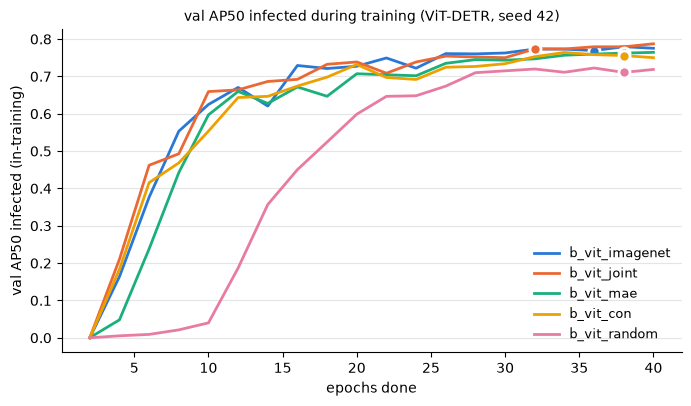

In [5]:
vit = [c for c in COLORS if c in curves.columns]
ax = plot_val_curves(curves[vit], COLORS, mark={r: int(runs.loc[r, 'best_epoch']) for r in vit})
ax.set_title('val AP50 infected during training (ViT-DETR, seed 42)', fontsize=10);

## Парний bootstrap різниць на test

Одні й ті самі 1000 ресемплів 120 test-зображень для обох моделей пари. `share_le_0` — частка ресемплів, де різниця ≤ 0. Без поправки на множинні порівняння; один seed.

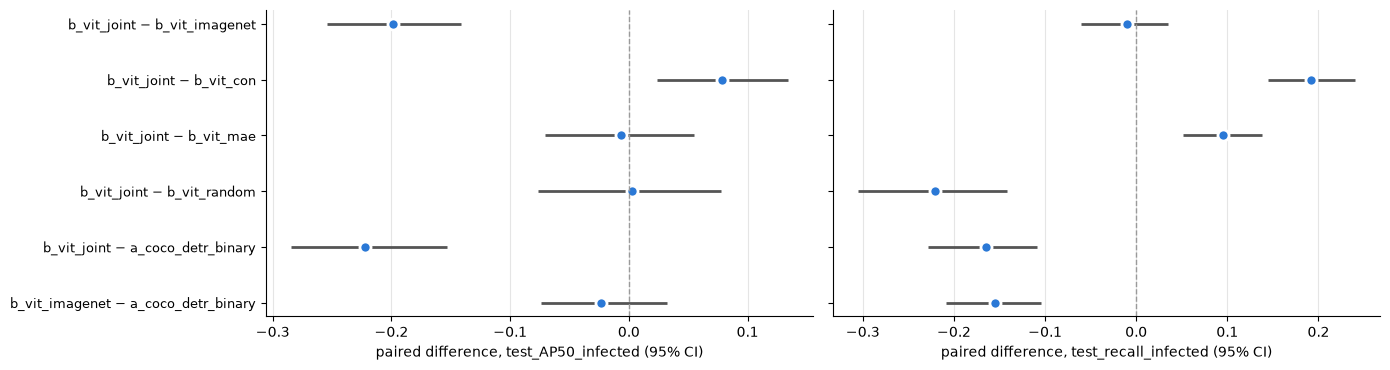

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_paired_diffs(diff, 'test_AP50_infected', axes[0])
plot_paired_diffs(diff, 'test_recall_infected', axes[1])
axes[1].set_yticklabels([])
fig.tight_layout()

In [7]:
diff[diff['metric'].isin(['test_AP50_infected', 'test_recall_infected'])].round(4)

,a,b,metric,diff,low,high,share_le_0,n
0,b_vit_joint,b_vit_imagenet,test_AP50_infected,-0.1983,-0.2540,-0.1415,1.000,1000
2,b_vit_joint,b_vit_imagenet,test_recall_infected,-0.0099,-0.0601,0.0354,0.700,1000
4,b_vit_joint,b_vit_con,test_AP50_infected,0.0781,0.0238,0.1341,0.001,1000
6,b_vit_joint,b_vit_con,test_recall_infected,0.1914,0.1448,0.2402,0.000,1000
8,b_vit_joint,b_vit_mae,test_AP50_infected,-0.0068,-0.0706,0.0546,0.561,1000
10,b_vit_joint,b_vit_mae,test_recall_infected,0.0957,0.0508,0.1381,0.001,1000
12,b_vit_joint,b_vit_random,test_AP50_infected,0.0028,-0.0766,0.0779,0.493,1000
14,b_vit_joint,b_vit_random,test_recall_infected,-0.2211,-0.3056,-0.1419,1.000,1000
16,b_vit_joint,a_coco_detr_binary,test_AP50_infected,-0.2219,-0.2849,-0.1535,1.000,1000
18,b_vit_joint,a_coco_detr_binary,test_recall_infected,-0.1650,-0.2289,-0.1088,1.000,1000


## Val vs test: розподіл infected-score (рисунки `diagnose_shift.py`)

a_coco_detr_binary


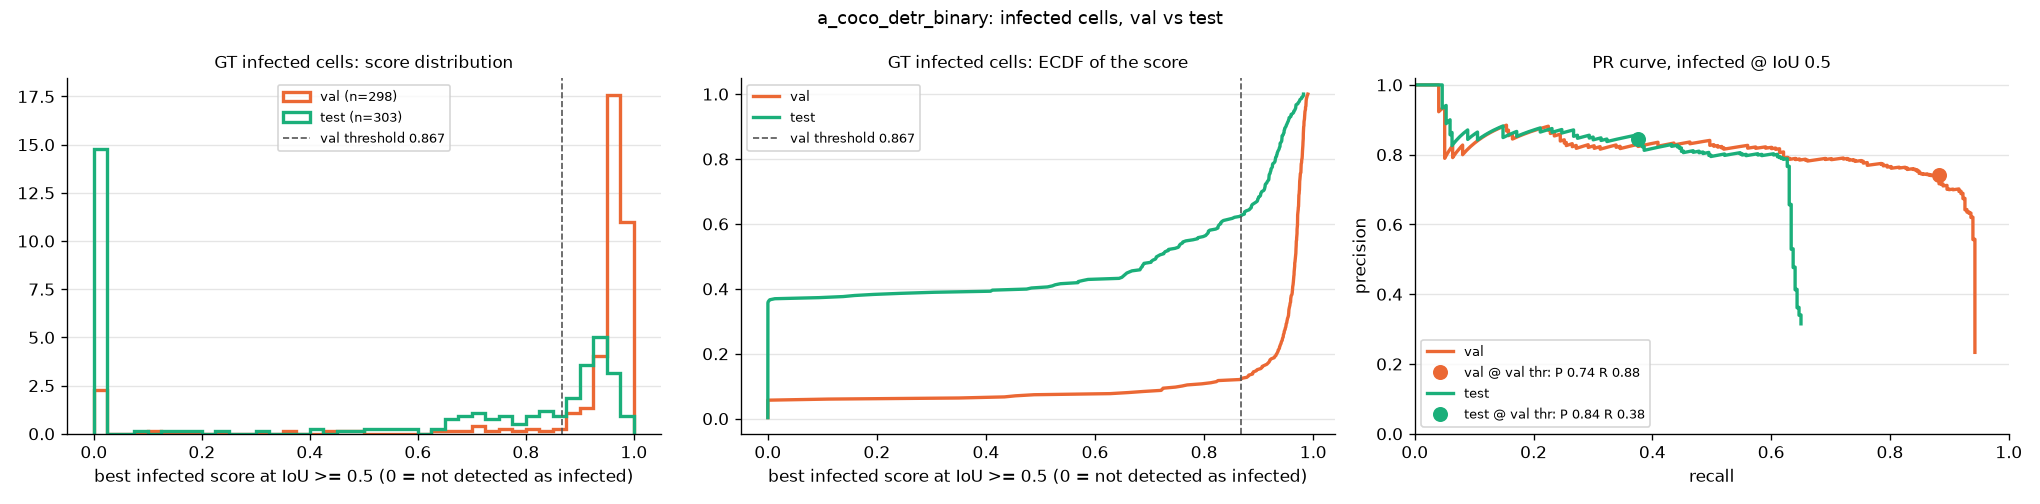

b_vit_random


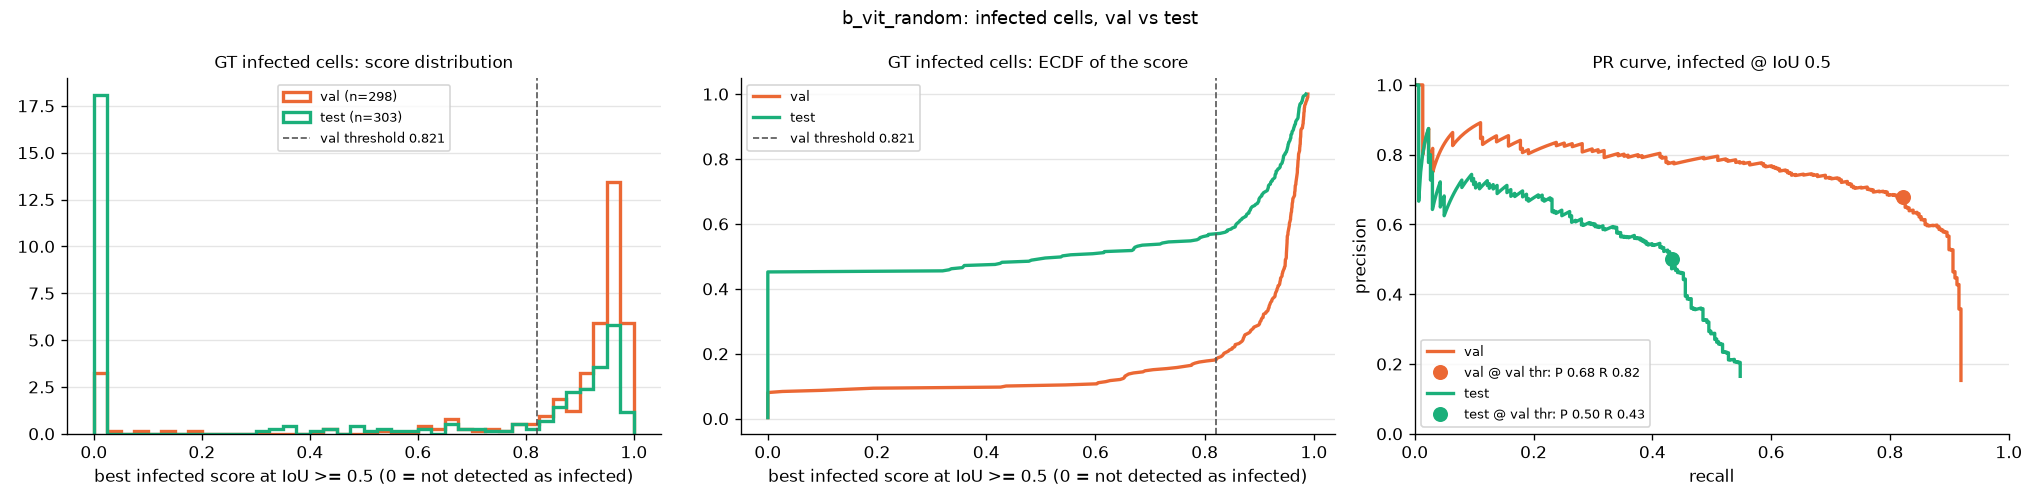

b_vit_imagenet


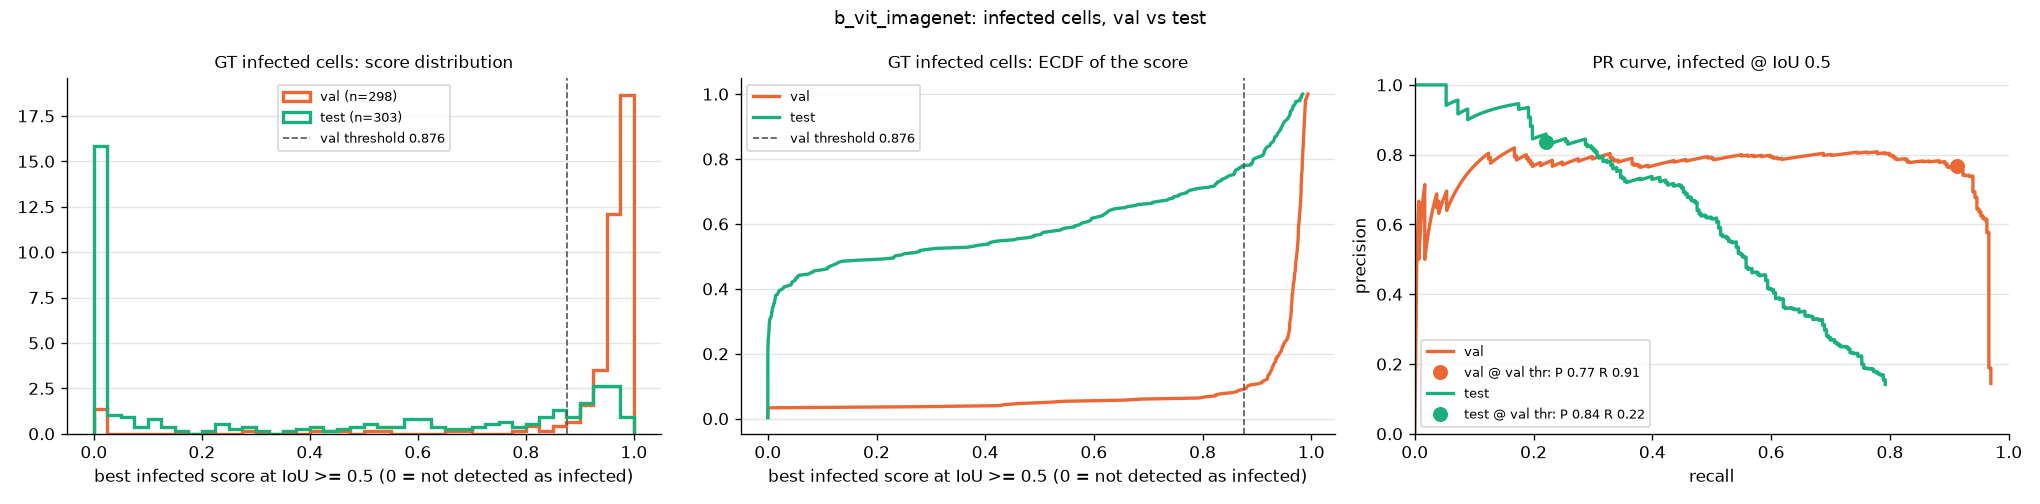

b_vit_mae


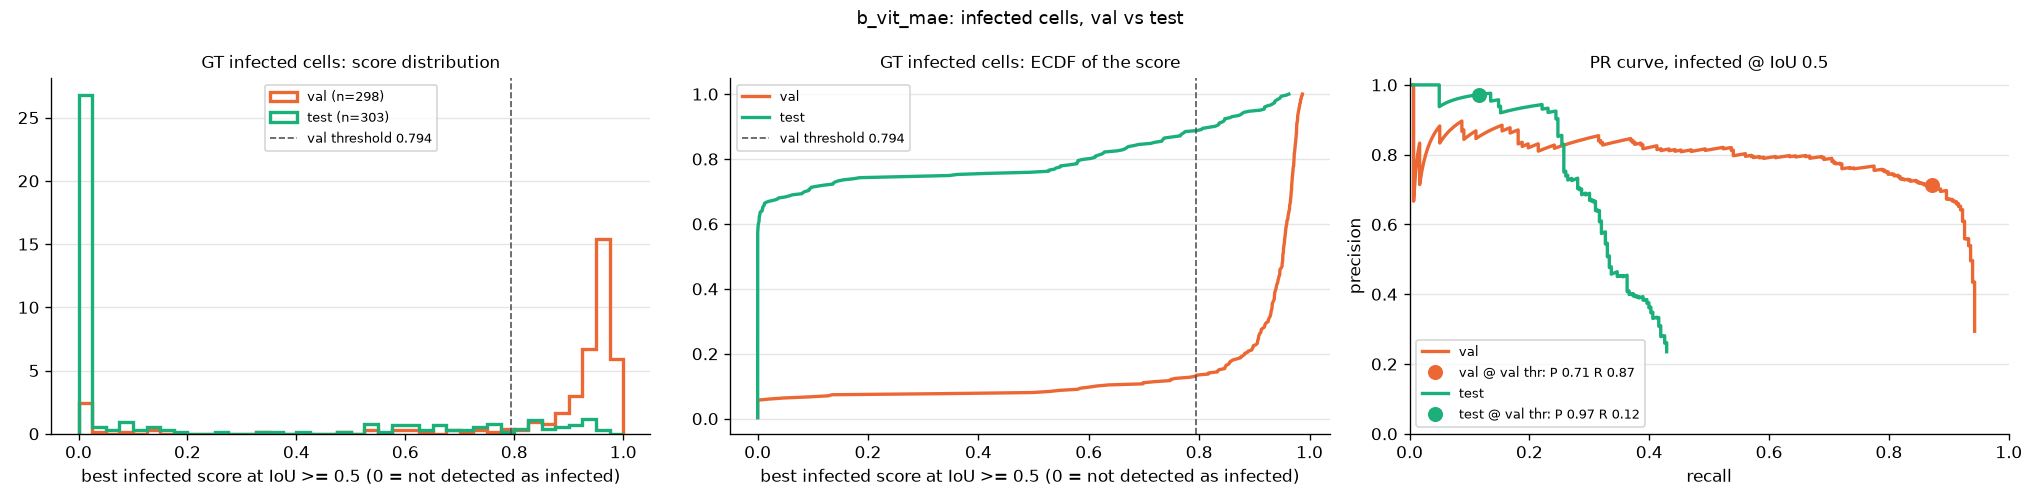

b_vit_con


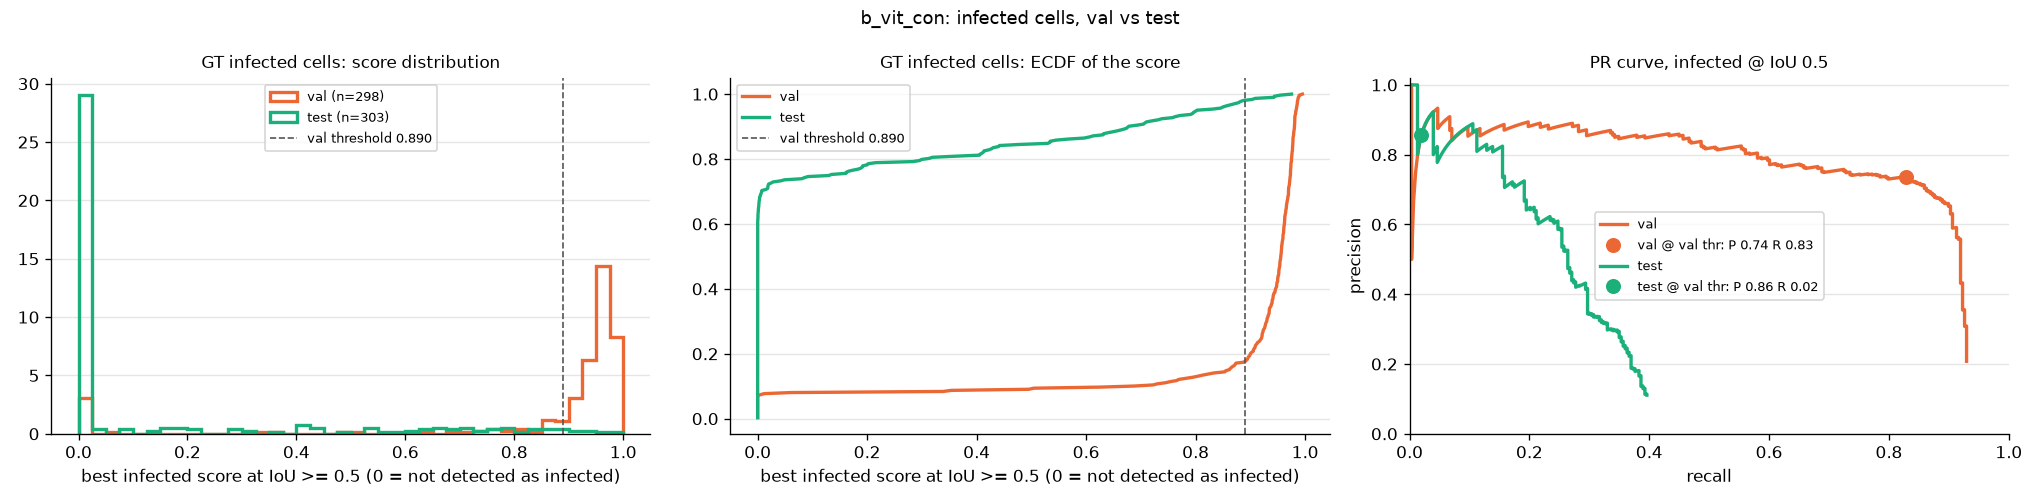

b_vit_joint


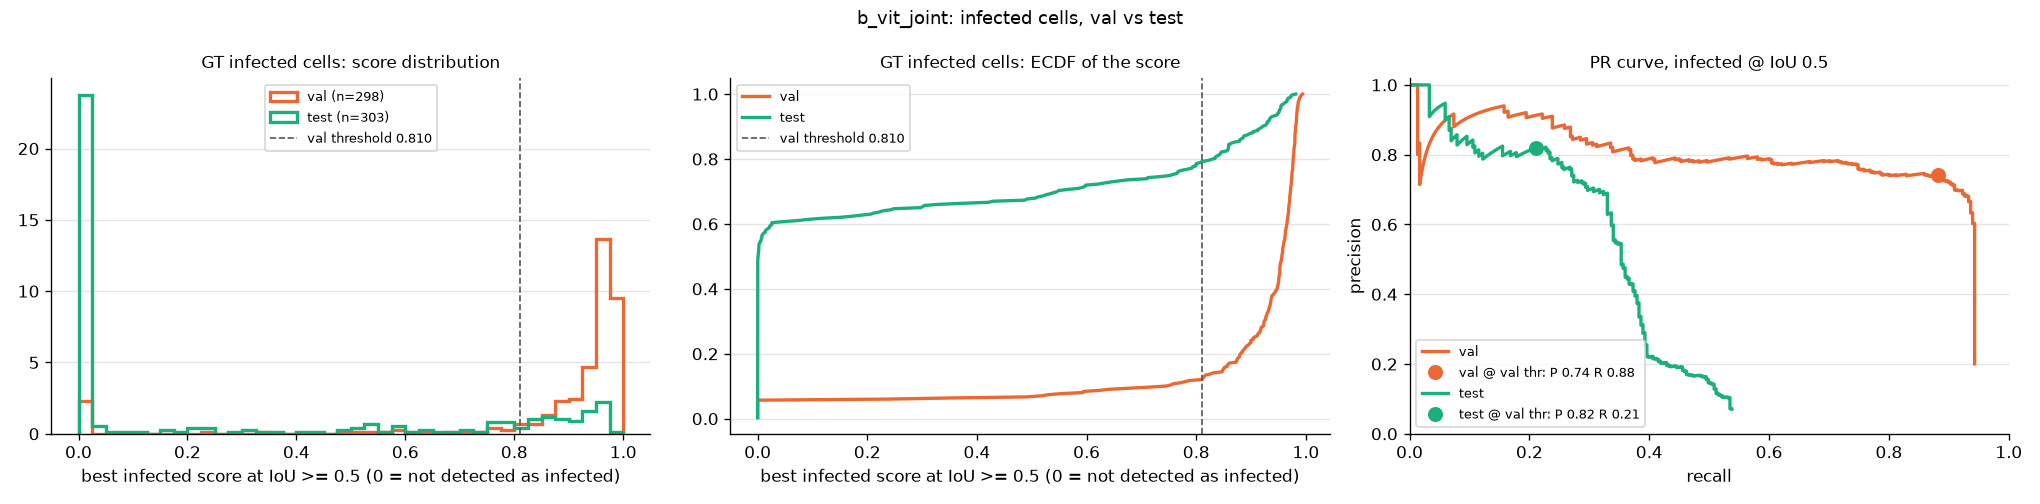

In [8]:
for r in runs.index:
    print(r)
    display(Image(filename=str(resolve_path('reports/figures') / f'shift_{r}.png'), width=1000))